# Question 1 – Raster Analysis

For every raster file in the folder `רסטרים לניתוח` this notebook extracts:

| Field | How it is obtained |
|---|---|
| **File name** | file system |
| **File type** (Aerial photo / Orthophoto / Elevation / Image) | rule-based classification of the metadata (see section 4) + visual check of the thumbnails |
| **Number of bands** | `dataset.count` |
| **Resolution (m)** | pixel size from the geotransform; converted from degrees to metres when the CRS is geographic |
| **Pixel type** | `dataset.dtypes` → unsigned integer / signed integer / floating point |
| **Pixel depth** | bits per sample (`uint8` → 8 bit, `uint16` → 16 bit, `float32` → 32 bit) |
| **Coordinate system** | `dataset.crs` (EPSG code + name) |

Libraries: `rasterio` (GDAL bindings – reading metadata & pixels), `numpy`, `pandas`, `matplotlib`, `scipy` (ndimage), `math`, `pathlib`.

## 1. Imports and settings

In [1]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

# Folder with the rasters (relative to this notebook – change if needed)
RASTER_DIR = Path("רסטרים לניתוח")
if not RASTER_DIR.exists():          # notebook placed inside the folder itself
    RASTER_DIR = Path(".")

EXTENSIONS = {".tif", ".tiff", ".jp2", ".img", ".ecw", ".png", ".jpg", ".jpeg"}
files = sorted(p for p in RASTER_DIR.iterdir() if p.suffix.lower() in EXTENSIONS)
print(f"rasterio {rasterio.__version__} | GDAL {rasterio.__gdal_version__}")
print(f"{len(files)} raster files found:")
for f in files:
    print(f"  {f.name:25s} {f.stat().st_size/1e6:10.1f} MB")

rasterio 1.5.0 | GDAL 3.12.1
7 raster files found:
  G_L_030_F_0137.jp2              15.0 MB
  G_L_034_F_0067.jp2              13.0 MB
  HDR_2580.tif                   899.3 MB
  HEF_2000.tif                   110.4 MB
  KSB_1626.jp2                   579.3 MB
  SHF_0117.tif                   177.8 MB
  TLY_1226.jp2                   267.0 MB


## 2. Raw metadata of each file

In [2]:
for f in files:
    with rasterio.open(f) as src:
        print("=" * 80)
        print(f.name)
        print(f"  driver      : {src.driver}")
        print(f"  size (WxH)  : {src.width} x {src.height}")
        print(f"  bands       : {src.count}")
        print(f"  dtypes      : {src.dtypes}")
        print(f"  pixel size  : {src.res}")
        print(f"  CRS         : {src.crs.to_string()[:120] if src.crs else None}")
        print(f"  bounds      : {tuple(round(b, 6) for b in src.bounds)}")
        print(f"  nodata      : {src.nodata}")
        print(f"  units       : {src.units}")
        print(f"  color interp: {[c.name for c in src.colorinterp]}")
        print(f"  tags        : {src.tags()}")

G_L_030_F_0137.jp2
  driver      : JP2OpenJPEG
  size (WxH)  : 19236 x 12836
  bands       : 3
  dtypes      : ('uint8', 'uint8', 'uint8')
  pixel size  : (1.7966305682247748e-08, 1.7966305682335806e-08)
  CRS         : EPSG:4326
  bounds      : (34.887306, 30.741241, 34.887652, 30.741472)
  nodata      : None
  units       : (None, None, None)
  color interp: ['red', 'green', 'blue']
  tags        : {}
G_L_034_F_0067.jp2
  driver      : JP2OpenJPEG
  size (WxH)  : 19236 x 12836
  bands       : 3
  dtypes      : ('uint8', 'uint8', 'uint8')
  pixel size  : (1.7966305682247748e-08, 1.7966305682335806e-08)
  CRS         : EPSG:4326
  bounds      : (34.956845, 30.606892, 34.957191, 30.607122)
  nodata      : None
  units       : (None, None, None)
  color interp: ['red', 'green', 'blue']
  tags        : {}
HDR_2580.tif
  driver      : GTiff
  size (WxH)  : 12789 x 11718
  bands       : 3
  dtypes      : ('uint16', 'uint16', 'uint16')
  pixel size  : (0.40000000000000047, 0.399999999999996)

## 3. Visual inspection (low-resolution previews)
Previews are read from the internal overviews (or decimated reads), so even the ~900 MB GeoTIFF loads quickly.

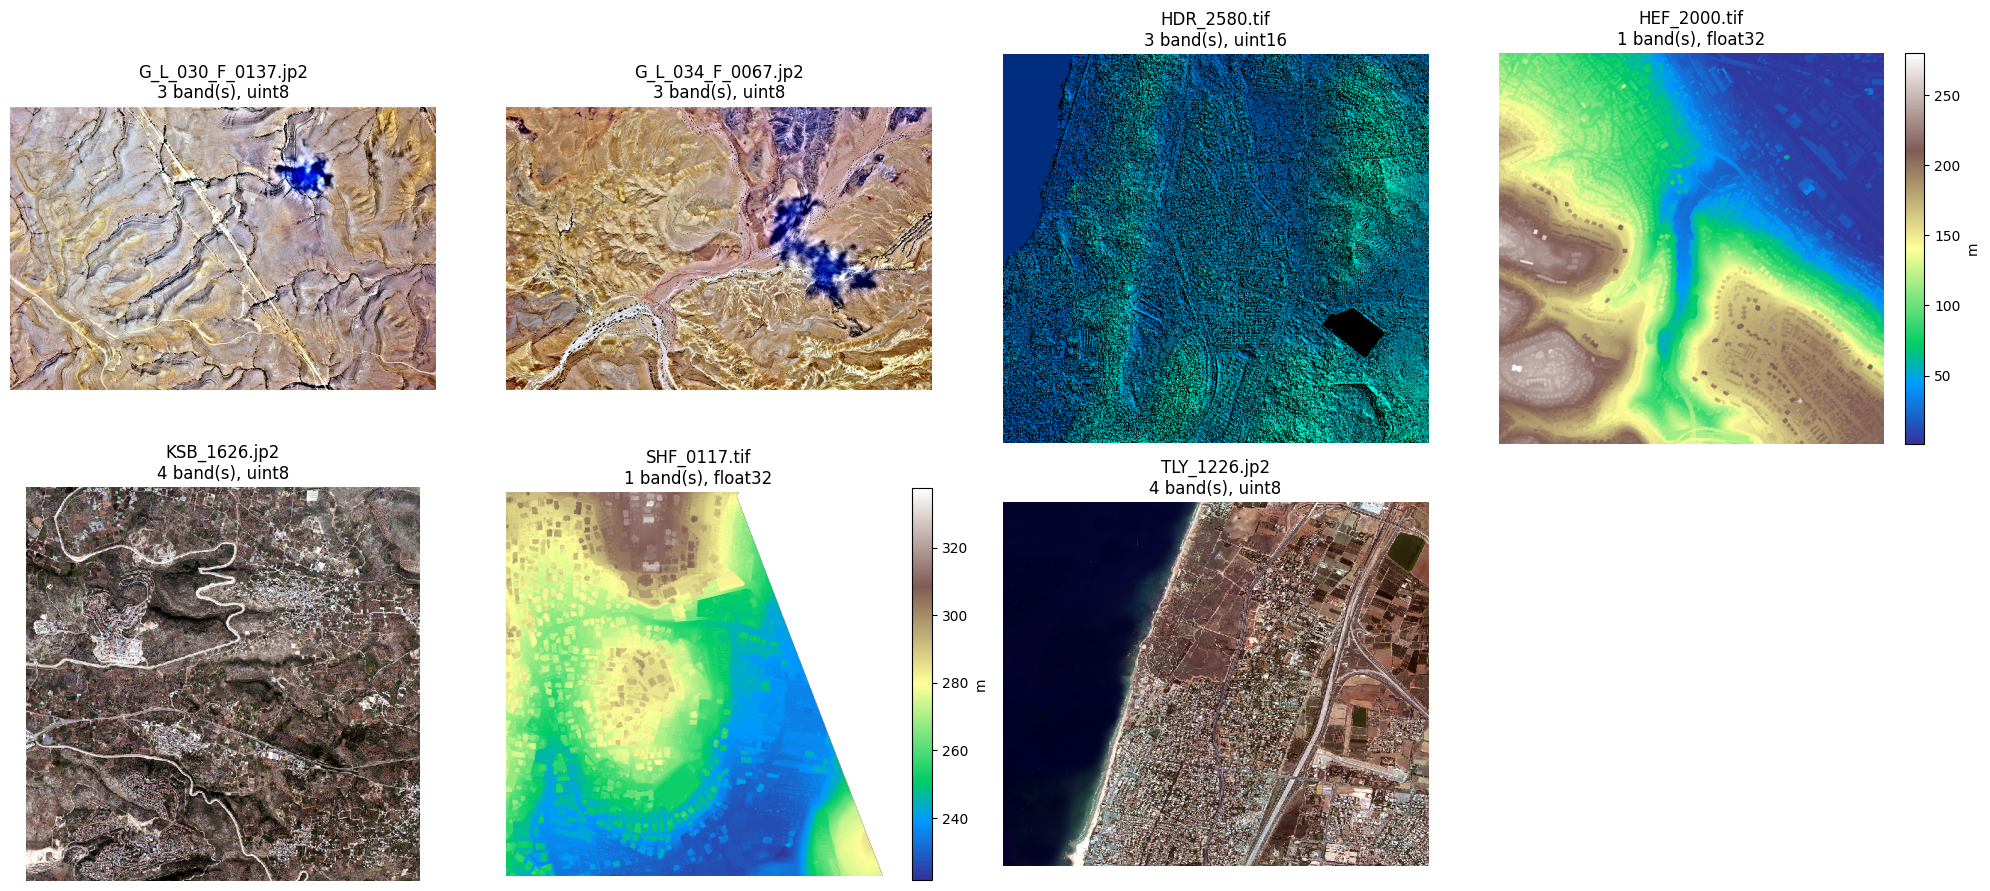

In [3]:
def read_preview(src, max_side=600):
    scale = max(src.width, src.height) / max_side
    shape = (src.count, max(1, int(src.height / scale)), max(1, int(src.width / scale)))
    return src.read(out_shape=shape, resampling=Resampling.nearest, masked=True)

def stretch(a):
    a = a.astype("float64").filled(np.nan) if np.ma.isMaskedArray(a) else a.astype("float64")
    lo, hi = np.nanpercentile(a, (2, 98))
    return np.clip((a - lo) / (hi - lo + 1e-12), 0, 1)

n = len(files)
cols = 4
rows = math.ceil(n / cols)
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4.5 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, f in zip(axes.flat, files):
    with rasterio.open(f) as src:
        d = read_preview(src)
        if src.count >= 3:
            ax.imshow(np.dstack([stretch(d[i]) for i in range(3)]))
        else:
            im = ax.imshow(d[0], cmap="terrain")
            plt.colorbar(im, ax=ax, fraction=0.046, label="m")
        ax.set_title(f"{f.name}\n{src.count} band(s), {src.dtypes[0]}")
plt.tight_layout()
plt.show()

## 4. Helper functions

**Resolution in metres** – for a projected CRS (e.g. Israel TM Grid, EPSG:2039) the pixel size is already in metres.
For a geographic CRS (degrees) it is converted using the WGS84 ellipsoid at the raster's centre latitude:
* 1° latitude  = M(φ)·π/180, where M is the meridional radius of curvature
* 1° longitude = N(φ)·cos(φ)·π/180, where N is the prime-vertical radius of curvature

**File-type classification rules**

| Type | Rule |
|---|---|
| **Elevation** (DSM/DTM) | single band, floating-point values, units = metre / plausible height values |
| **Image** | no georeferencing at all (no CRS and identity geotransform) – just a picture |
| **Aerial photo** (raw, not rectified) | multi-band but the georeferencing is only nominal: the pixel size is physically impossible for aerial imagery (< 1 cm) – the frame naming `G_L_<strip>_F_<frame>` also indicates a raw camera frame |
| **Orthophoto** | multi-band (RGB / RGB+NIR), georeferenced with a realistic ground pixel size (centimetres to metres) |

In [4]:
A_WGS84 = 6378137.0
E2_WGS84 = 6.69437999014e-3

def degree_lengths_m(lat_deg):
    """Length in metres of 1 degree of longitude and of latitude at a given latitude (WGS84)."""
    phi = math.radians(lat_deg)
    w = math.sqrt(1 - E2_WGS84 * math.sin(phi) ** 2)
    N = A_WGS84 / w                                  # prime vertical radius
    M = A_WGS84 * (1 - E2_WGS84) / w ** 3            # meridional radius
    return N * math.cos(phi) * math.pi / 180, M * math.pi / 180

def looks_geographic(src):
    """True if the CRS is geographic, or undefined but the coordinates are clearly lon/lat degrees."""
    if src.crs and src.crs.is_geographic:
        return True
    b = src.bounds
    return (src.crs is None or not src.crs.is_projected) and -180 <= b.left <= 180 and -90 <= b.bottom <= 90 and src.res[0] < 0.01

def resolution_m(src):
    rx, ry = src.res
    if looks_geographic(src):
        lat_c = (src.bounds.top + src.bounds.bottom) / 2
        mx, my = degree_lengths_m(lat_c)
        return rx * mx, ry * my
    return rx, ry

def pixel_type(dtype):
    k = np.dtype(dtype).kind
    return {"u": "Unsigned integer", "i": "Signed integer", "f": "Floating point", "c": "Complex"}[k] + f" ({dtype})"

def pixel_depth(dtype):
    return f"{np.dtype(dtype).itemsize * 8} bit"

def crs_description(src):
    crs = src.crs
    if crs is None:
        return "None (not georeferenced)"
    epsg = crs.to_epsg()
    if epsg:
        name = crs.to_wkt().split('"')[1]
        return f"EPSG:{epsg} – {name}"
    # undefined / local CS (e.g. old ECW/ER-Mapper header)
    if looks_geographic(src):
        return "LOCAL_CS (undefined in file); coordinates are geographic lon/lat degrees ≈ WGS84"
    return "LOCAL_CS (undefined)"

def has_georef(src):
    return src.crs is not None or not src.transform.is_identity

def classify(src, res_m):
    kind = np.dtype(src.dtypes[0]).kind
    if src.count == 1 and kind == "f":
        return "Elevation (DSM/DTM)"
    if not has_georef(src):
        return "Image (no georeference)"
    if min(res_m) < 0.01:          # < 1 cm per pixel: nominal georeference only
        return "Aerial photo (raw frame)"
    return "Orthophoto"


## 5. Build the table

In [5]:
records = []
for f in files:
    with rasterio.open(f) as src:
        rx, ry = resolution_m(src)
        dtypes = set(src.dtypes)
        dt = src.dtypes[0]
        records.append({
            "File name": f.name,
            "File type": classify(src, (rx, ry)),
            "Bands": src.count,
            "Resolution (m)": round((rx + ry) / 2, 3) if abs(rx - ry) / max(rx, ry) < 0.05
                              else f"{rx:.3f} x {ry:.3f}",
            "Pixel type": pixel_type(dt) if len(dtypes) == 1 else ", ".join(sorted(dtypes)),
            "Pixel depth": pixel_depth(dt),
            "Coordinate system": crs_description(src),
        })

table = pd.DataFrame(records)
pd.set_option("display.max_colwidth", None)
table

,File name,File type,Bands,Resolution (m),Pixel type,Pixel depth,Coordinate system
0,G_L_030_F_0137.jp2,Aerial photo (raw frame),3,0.002 x 0.002,Unsigned integer (uint8),8 bit,EPSG:4326 – WGS 84
1,G_L_034_F_0067.jp2,Aerial photo (raw frame),3,0.002 x 0.002,Unsigned integer (uint8),8 bit,EPSG:4326 – WGS 84
2,HDR_2580.tif,Orthophoto,3,0.4,Unsigned integer (uint16),16 bit,EPSG:2039 – Israel 1993 / Israeli TM Grid
3,HEF_2000.tif,Elevation (DSM/DTM),1,0.4,Floating point (float32),32 bit,EPSG:2039 – Israel 1993 / Israeli TM Grid
4,KSB_1626.jp2,Orthophoto,4,0.2,Unsigned integer (uint8),8 bit,EPSG:2039 – Israel 1993 / Israeli TM Grid
5,SHF_0117.tif,Elevation (DSM/DTM),1,0.15,Floating point (float32),32 bit,EPSG:2039 – Israel 1993 / Israeli TM Grid
6,TLY_1226.jp2,Orthophoto,4,0.169 x 0.199,Unsigned integer (uint8),8 bit,LOCAL_CS (undefined in file); coordinates are geographic lon/lat degrees ≈ WGS84


## 6. Notes on the results

* **G_L_030_F_0137.jp2, G_L_034_F_0067.jp2 – Aerial photos.** Raw camera frames (naming: strip *030/034*, frame *0137/0067*; 19236×12836 px, a typical large-format digital aerial camera frame). The file carries only a nominal EPSG:4326 georeference with a pixel size of ~1.8·10⁻⁸ ° (≈ 2 mm), which is physically meaningless – the image was never orthorectified, so its true ground resolution cannot be read from the file (it depends on flight height and camera focal length).
* **HDR_2580.tif – Orthophoto**, RGB, 16-bit unsigned (values only reach ~252, i.e. 8-bit data stored in 16-bit; band 1 is empty), 0.4 m, Israel TM Grid (EPSG:2039). Written by Global Mapper.
* **KSB_1626.jp2 – Orthophoto**, 4 bands (RGB + NIR), 8-bit, 0.2 m, ITM (EPSG:2039), a 5 km × 5 km tile.
* **TLY_1226.jp2 – Orthophoto**, 4 bands, 8-bit. The CRS is stored as an undefined `LOCAL_CS` (old ER-Mapper/ECW header), but the registration values (origin 34.789° E, 32.213° N; cell 1.7966·10⁻⁶ °) are WGS84 geographic degrees. 1.7966·10⁻⁶ ° = 0.2 m / 111 320 m, i.e. a nominal **0.2 m** pixel (actual ground size at 32° N ≈ 0.17 m E-W × 0.20 m N-S).
* **HEF_2000.tif, SHF_0117.tif – Elevation models** (single band, 32-bit float, units *metre*, NoData −9999 / −32767), ITM, 0.4 m and 0.15 m respectively.

## 7. Export the table

In [6]:
table.to_csv("raster_analysis_table.csv", index=False, encoding="utf-8-sig")
print("Saved raster_analysis_table.csv")

Saved raster_analysis_table.csv


# Question 2 – Histogram analysis

Every file is read at a reduced size (longest side about 1500 px, read from the internal overviews / decimated) and stored in a cache, so Q2 and Q3 share one read per file.
For colour rasters the histogram is built per band over the 0–255 range. For elevation rasters (float) it is built from 256 bins between min and max, with NoData excluded.

A histogram counts as **not representing a uniform (well-spread) colour distribution** if at least one band meets one of these rules:

| Rule | Metric | Threshold |
|---|---|---|
| Empty / constant band | standard deviation of the band | = 0 |
| Narrow histogram (low contrast) | Shannon entropy (max 8 bit) **or** share of the 0–255 range used by the 1st–99th percentiles | entropy < 6 bit or range < 40 % |
| Dominant spike | share of pixels in the most frequent value | > 5 % |
| Clipping | share of pixels at the minimum (0) or maximum (255) value | ≥ 1 % |

In [7]:
from scipy import ndimage as ndi
from matplotlib.colors import rgb_to_hsv

PREVIEW_SIDE = 1500
cache = {}
for f in files:
    with rasterio.open(f) as src:
        arr = read_preview(src, PREVIEW_SIDE)            # masked array (NoData masked)
        cache[f.name] = {"data": arr, "count": src.count,
                         "is_float": np.dtype(src.dtypes[0]).kind == "f"}
    print(f"{f.name:22s} preview shape {arr.shape}")

G_L_030_F_0137.jp2     preview shape (3, 1000, 1500)
G_L_034_F_0067.jp2     preview shape (3, 1000, 1500)


HDR_2580.tif           preview shape (3, 1374, 1500)
HEF_2000.tif           preview shape (1, 1500, 1479)


KSB_1626.jp2           preview shape (4, 1500, 1500)
SHF_0117.tif           preview shape (1, 1500, 1500)


TLY_1226.jp2           preview shape (4, 1283, 1500)


In [8]:
def band_histogram(x, is_float):
    """x: 1-D array of valid values. Returns (counts, bin_centres)."""
    if is_float:
        counts, edges = np.histogram(x, bins=256)
        return counts, (edges[:-1] + edges[1:]) / 2
    counts = np.bincount(x.astype(np.int64), minlength=256)[:256]
    return counts, np.arange(256)

def hist_metrics(x, is_float):
    counts, centres = band_histogram(x, is_float)
    p = counts / counts.sum()
    entropy = -(p[p > 0] * np.log2(p[p > 0])).sum()
    if is_float:
        rng = 100.0                                       # bins span min..max by construction
        clip = 0.0
    else:
        lo, hi = np.percentile(x, (1, 99))
        rng = (hi - lo) / 255 * 100
        clip = max((x == 0).mean(), (x >= 255).mean()) * 100
    return {"std": float(x.std()), "entropy": float(entropy), "range_%": float(rng),
            "peak_%": float(p.max() * 100), "peak_value": float(centres[p.argmax()]),
            "clip_%": float(clip)}

hist_rows = []
for name, c in cache.items():
    d = c["data"]
    for b in range(c["count"]):
        x = d[b].compressed()
        m = hist_metrics(x, c["is_float"])
        reasons = []
        if m["std"] == 0:
            reasons.append("empty/constant band")
        elif m["entropy"] < 6 or m["range_%"] < 40:
            reasons.append("narrow histogram (low contrast)")
        if m["std"] > 0 and m["peak_%"] > 5:
            reasons.append(f"dominant spike at {m['peak_value']:g}")
        if m["clip_%"] >= 1:
            reasons.append("clipping at 0/255")
        hist_rows.append({"File": name, "Band": b + 1, **{k: round(v, 2) for k, v in m.items()},
                          "Non-uniform reasons": ", ".join(reasons)})

hist_df = pd.DataFrame(hist_rows)
hist_df

,File,Band,std,entropy,range_%,peak_%,peak_value,clip_%,Non-uniform reasons
0,G_L_030_F_0137.jp2,1,10.70,4.73,25.88,8.66,187.00,0.00,"narrow histogram (low contrast), dominant spike at 187"
1,G_L_030_F_0137.jp2,2,9.39,4.84,22.75,8.02,156.00,0.00,"narrow histogram (low contrast), dominant spike at 156"
2,G_L_030_F_0137.jp2,3,9.05,4.95,21.18,6.43,121.00,0.00,"narrow histogram (low contrast), dominant spike at 121"
3,G_L_034_F_0067.jp2,1,12.80,5.35,27.84,5.50,185.00,0.00,"narrow histogram (low contrast), dominant spike at 185"
4,G_L_034_F_0067.jp2,2,11.85,5.41,25.88,5.74,144.00,0.00,"narrow histogram (low contrast), dominant spike at 144"
5,G_L_034_F_0067.jp2,3,10.67,5.37,23.14,4.45,111.00,0.00,narrow histogram (low contrast)
6,HDR_2580.tif,1,0.00,-0.00,0.00,100.00,0.00,100.00,"empty/constant band, clipping at 0/255"
7,HDR_2580.tif,2,52.90,6.62,79.22,19.04,0.00,19.04,"dominant spike at 0, clipping at 0/255"
8,HDR_2580.tif,3,77.82,6.97,96.08,18.91,0.00,18.91,"dominant spike at 0, clipping at 0/255"
9,HEF_2000.tif,1,73.88,7.64,100.00,3.68,3.66,0.00,


### Histograms of all files

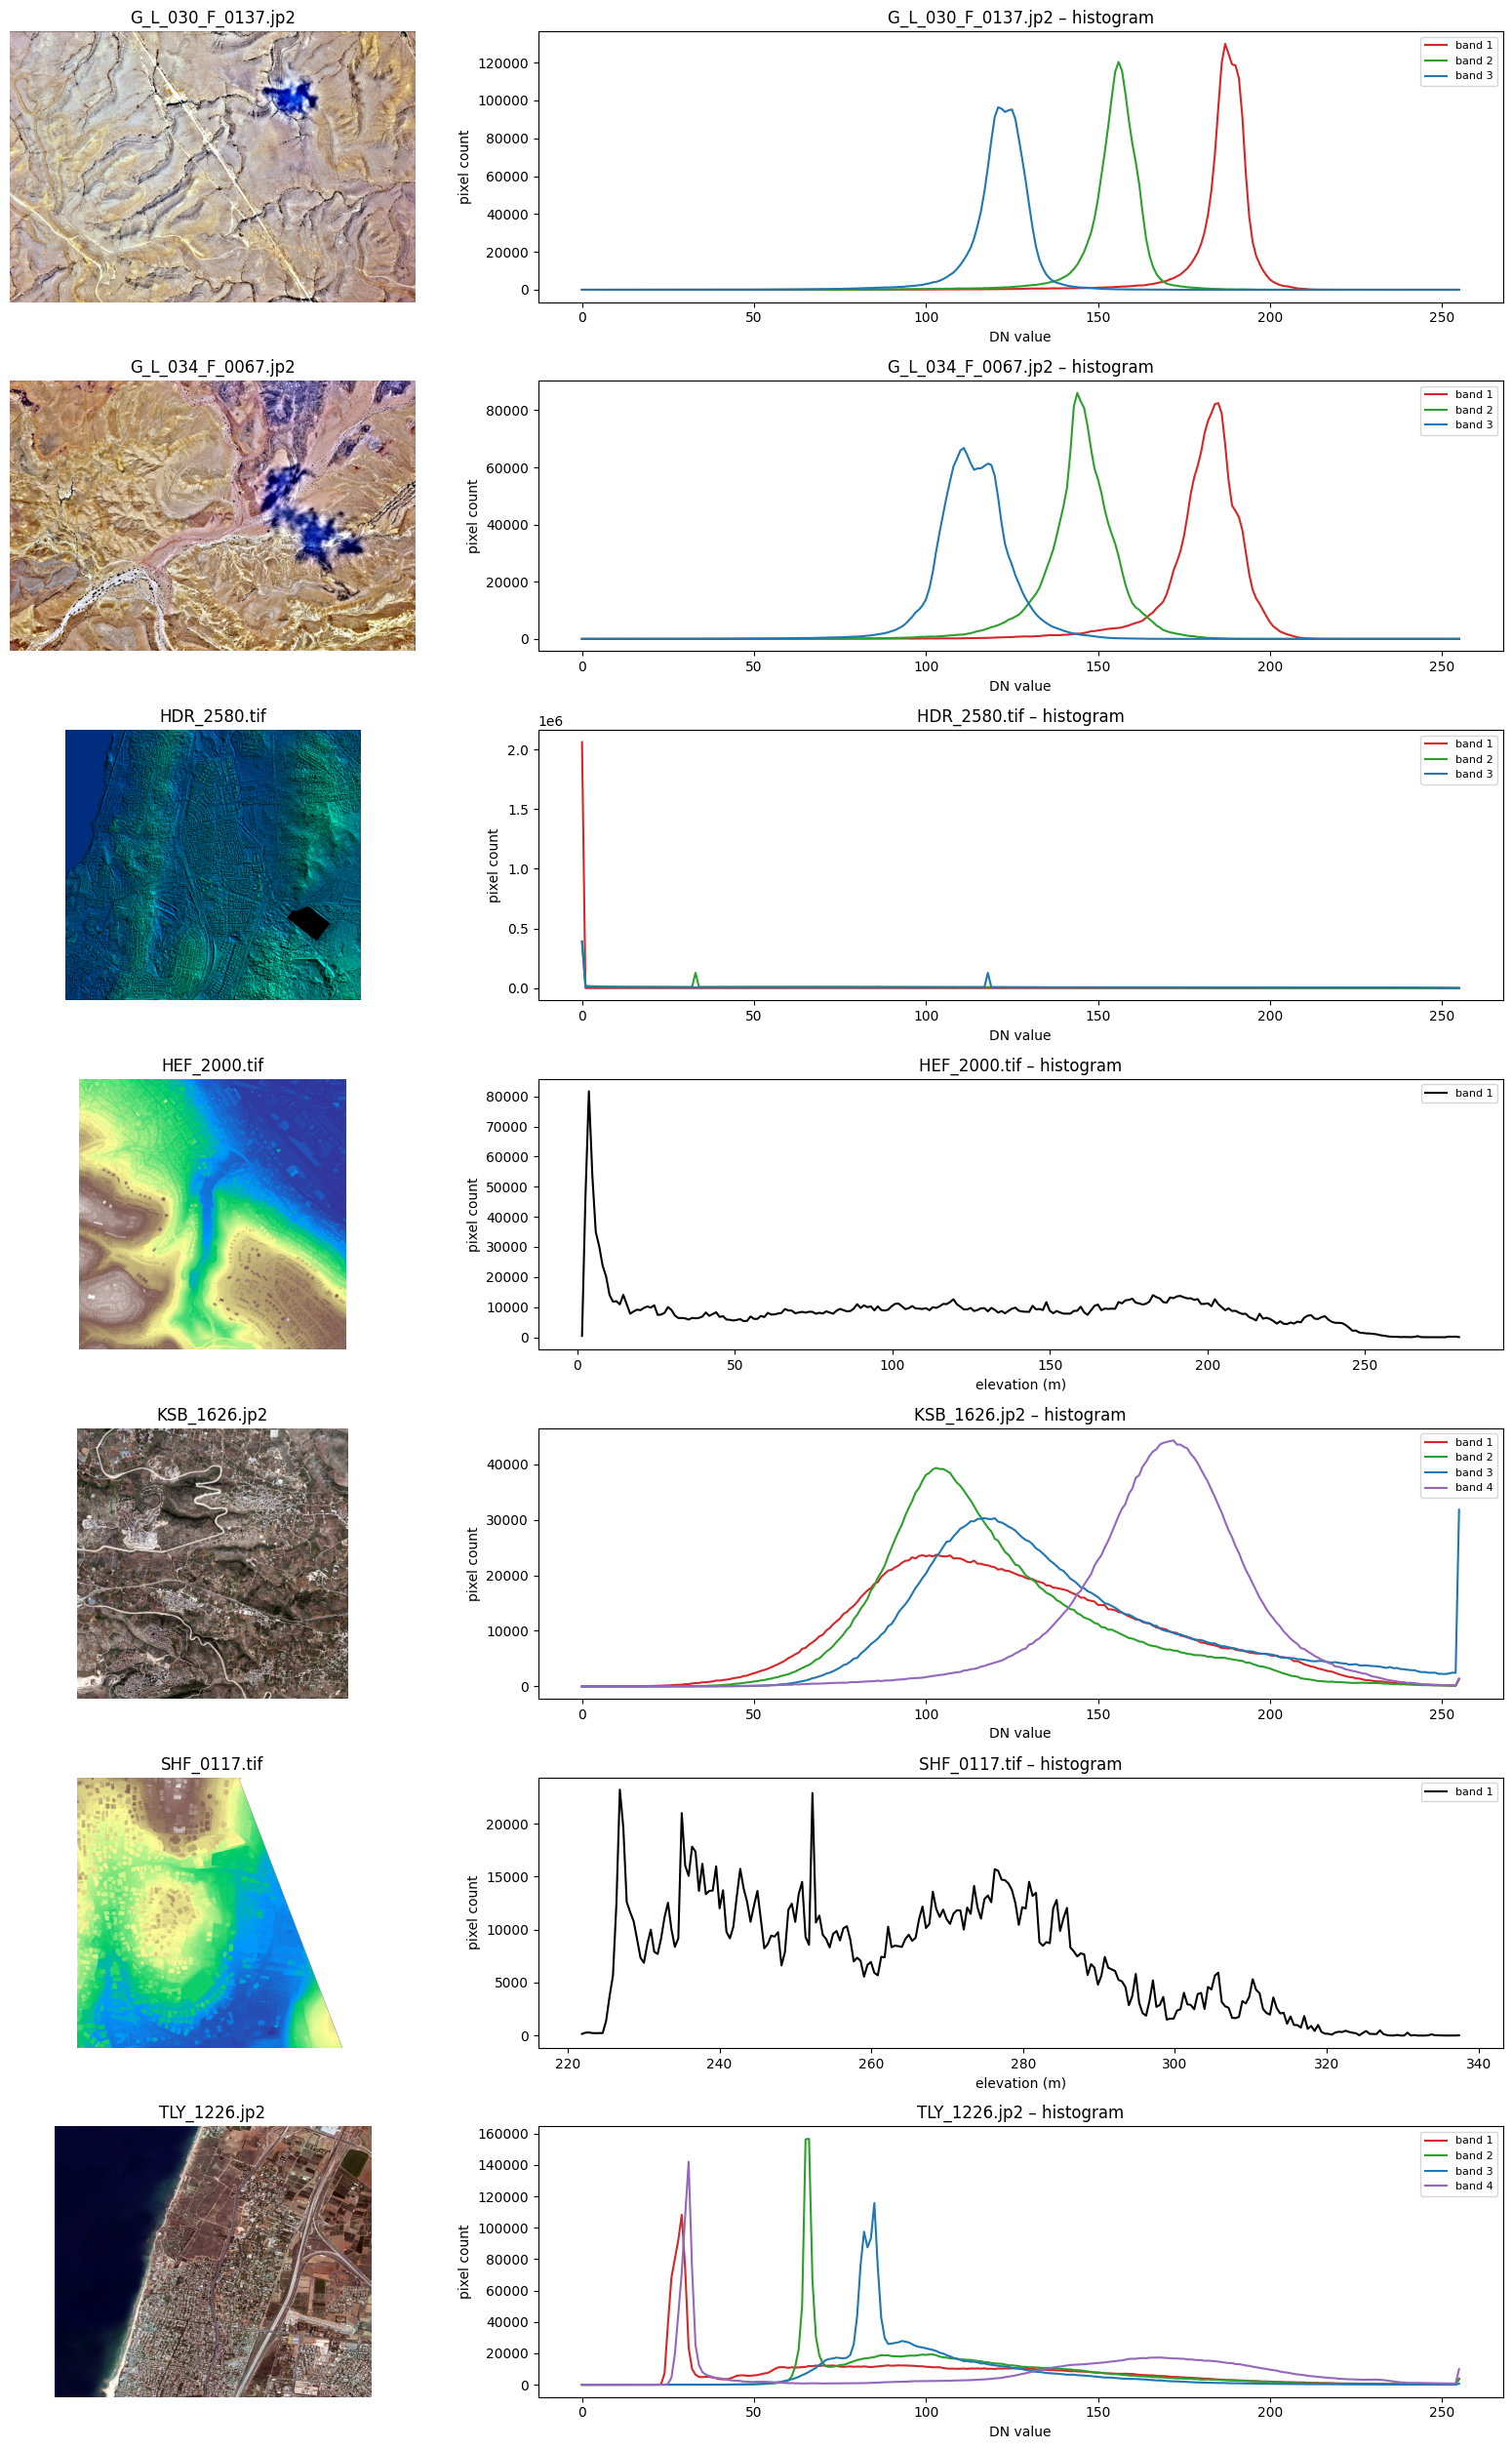

In [9]:
band_colors = {3: ["tab:red", "tab:green", "tab:blue"], 4: ["tab:red", "tab:green", "tab:blue", "tab:purple"]}
fig, axes = plt.subplots(len(cache), 2, figsize=(16, 3.6 * len(cache)),
                         gridspec_kw={"width_ratios": [1, 2]})
for row, (name, c) in zip(axes, cache.items()):
    d = c["data"]
    if c["count"] >= 3:
        row[0].imshow(np.dstack([stretch(d[i]) for i in range(3)]))
    else:
        row[0].imshow(d[0], cmap="terrain")
    row[0].set_title(name); row[0].axis("off")
    for b in range(c["count"]):
        counts, centres = band_histogram(d[b].compressed(), c["is_float"])
        col = band_colors.get(c["count"], ["k"])[b]
        row[1].plot(centres, counts, color=col, label=f"band {b+1}")
    row[1].set_xlabel("elevation (m)" if c["is_float"] else "DN value")
    row[1].set_ylabel("pixel count"); row[1].legend(fontsize=8)
    row[1].set_title(f"{name} – histogram")
plt.tight_layout()
plt.show()

### Summary per file

In [10]:
q2 = (hist_df.groupby("File")["Non-uniform reasons"]
        .apply(lambda s: "; ".join(sorted({r for v in s for r in v.split(", ") if r})))
        .reset_index())
q2["Uniform colour distribution?"] = np.where(q2["Non-uniform reasons"] == "", "Yes", "No")
q2 = q2[["File", "Uniform colour distribution?", "Non-uniform reasons"]]
q2

,File,Uniform colour distribution?,Non-uniform reasons
0,G_L_030_F_0137.jp2,No,dominant spike at 121; dominant spike at 156; dominant spike at 187; narrow histogram (low contrast)
1,G_L_034_F_0067.jp2,No,dominant spike at 144; dominant spike at 185; narrow histogram (low contrast)
2,HDR_2580.tif,No,clipping at 0/255; dominant spike at 0; empty/constant band
3,HEF_2000.tif,Yes,
4,KSB_1626.jp2,No,clipping at 0/255
5,SHF_0117.tif,Yes,
6,TLY_1226.jp2,No,dominant spike at 29; dominant spike at 31; dominant spike at 66; dominant spike at 85


### Interpretation – why are these histograms not uniform?

| File | What the histogram shows | Probable reason |
|---|---|---|
| **G_L_030_F_0137.jp2, G_L_034_F_0067.jp2** | Very narrow, sharp peaks per band (about 130–200 for R, std about 10). Only about 25 % of the dynamic range is used and entropy is about 5 bit. The three bands are separated (R > G > B) | Raw aerial photos (not radiometrically stretched) of a **homogeneous desert** surface (Negev, sand/loess: one dominant colour). Atmospheric **haze**/scattering at flight height lowers contrast, and the camera exposure is set for the whole bright frame. The clouds and cloud shadows add a small dark-bluish tail |
| **HDR_2580.tif** | Band 1 (red) is **completely empty** (all 0). Bands 2–3 have a huge spike at 0 (about 19 % of pixels) | A **missing/zeroed band** (wrong band mapping or a failed export: Global Mapper, 8-bit data written into a 16-bit file). The 0-spike comes from shadows and dark areas **clipped to 0** and from a **NoData polygon** (black area with no data) |
| **TLY_1226.jp2** | Several very sharp narrow peaks (e.g. band 2 at 66, band 3 at 85, bands 1/4 at about 30) on top of a broad distribution | A large **homogeneous water body** (Mediterranean Sea, about 30 % of the tile) gives almost identical values. The histogram is bimodal (sea vs. city). Not a sensor fault but a scene effect |
| **KSB_1626.jp2** | Broad, healthy distribution, but band 3 has a spike at **255** (about 1.4 %) | **Saturation / overexposure** of very bright surfaces (white roofs, concrete, quarries). The dynamic range of the sensor is exceeded, and values are clipped at the 8-bit maximum |
| HEF_2000.tif, SHF_0117.tif | Elevation values spread over the whole range | DEMs: the distribution reflects terrain. HEF has a small peak near 0–5 m (flat low valley floor/sea-level area), which is natural. SHF's NoData (−32767) is excluded |

# Question 3 – Defect detection (valid / invalid)

Each file is tested automatically for the following defects (on the cached previews):

| Defect | Detection rule |
|---|---|
| **Missing data** | NoData pixels ≥ 1 %, **or** a band that is entirely empty (std = 0), **or** a connected block of pixels that are 0 in all bands covering ≥ 0.2 % of the image |
| **Dark / black areas** (clipped shadows) | pixels that are 0 in every valid band ≥ 5 % |
| **Burnt (overexposed) areas** | pixels clipped white (≥ 254 in **all three** RGB bands) ≥ 1 %, **or** a connected block of such pixels ≥ 0.2 % of the image. Clipping in a single band on scattered bright pixels (roofs, concrete) is reported as a metric but is not a defect: the other bands still carry the information |
| **Clouds / cloud shadow** | blobs of pixels whose HSV saturation is far below the scene (S < median − 4·MAD). After morphological opening, the largest connected blob must be ≥ 0.5 % of the image. Clouds and their shadows are greyish-blue and low-saturation compared with natural ground cover |

Colour-based tests (dark, burnt, clouds) are not applied to elevation models. Only Missing data is relevant for them. A file with at least one defect is **Invalid**.

In [11]:
def largest_blob_pct(mask, opening=3):
    if opening:
        mask = ndi.binary_opening(mask, iterations=opening)
    lab, n = ndi.label(mask)
    if n == 0:
        return 0.0, mask
    sizes = ndi.sum(mask, lab, range(1, n + 1))
    return 100 * sizes.max() / mask.size, mask

def detect_defects(c):
    d = c["data"]
    nodata_pct = 100 * np.ma.getmaskarray(d).all(axis=0).mean()
    m = {"NoData %": nodata_pct}
    defects = []
    if c["is_float"]:                                    # elevation model
        if nodata_pct >= 1:
            defects.append("Missing data (NoData area)")
        return m, defects, {}

    v = d.filled(0).astype(float)
    empty_bands = [b + 1 for b in range(c["count"]) if v[b].std() == 0]
    valid = [b for b in range(c["count"]) if b + 1 not in empty_bands]
    allzero = (v[valid] == 0).all(axis=0)
    zero_blob, zero_mask = largest_blob_pct(allzero, opening=5)
    sat_any = (v[:3] >= 254).any(axis=0)                # clipped in at least one colour band
    sat = (v[:3] >= 254).all(axis=0)                    # burnt = clipped white in all RGB bands
    burnt_blob, _ = largest_blob_pct(sat, opening=1)
    m.update({"Empty bands": str(empty_bands) if empty_bands else "",
              "Black (0) %": 100 * allzero.mean(),
              "Largest black block %": zero_blob,
              "Clipped (any RGB band) %": 100 * sat_any.mean(),
              "Burnt (all RGB) %": 100 * sat.mean(),
              "Largest burnt block %": burnt_blob})

    if nodata_pct >= 1 or empty_bands or zero_blob >= 0.2:
        parts = []
        if empty_bands: parts.append(f"empty band {empty_bands}")
        if zero_blob >= 0.2: parts.append("black NoData block")
        if nodata_pct >= 1: parts.append("NoData area")
        defects.append("Missing data (" + ", ".join(parts) + ")")
    if m["Black (0) %"] >= 5:
        defects.append("Dark areas (shadows clipped to 0)")
    if m["Burnt (all RGB) %"] >= 1 or burnt_blob >= 0.2:
        defects.append("Burnt / overexposed areas")

    cloud_blob, cloud_mask = 0.0, np.zeros(allzero.shape, bool)
    if not empty_bands:                                   # saturation is meaningless with a missing band
        S = rgb_to_hsv(np.clip(np.dstack(v[:3]) / 255, 0, 1))[..., 1]
        med = np.median(S); mad = np.median(np.abs(S - med)) + 1e-6
        cloud_blob, cloud_mask = largest_blob_pct(S < med - 4 * mad, opening=3)
    m["Largest cloud-like blob %"] = cloud_blob
    if cloud_blob >= 0.5:
        defects.append("Clouds / cloud shadow")
    masks = {"black": zero_mask, "saturated": sat, "cloud": cloud_mask}
    return m, defects, masks

q3_rows, masks_all = [], {}
for name, c in cache.items():
    m, defects, masks = detect_defects(c)
    masks_all[name] = masks
    q3_rows.append({"File": name, **{k: (round(v, 2) if isinstance(v, float) else v) for k, v in m.items()},
                    "Status": "Invalid" if defects else "Valid",
                    "Defect type": "; ".join(defects)})
q3_metrics = pd.DataFrame(q3_rows).fillna("")
q3_metrics

,File,NoData %,Empty bands,Black (0) %,Largest black block %,Clipped (any RGB band) %,Burnt (all RGB) %,Largest burnt block %,Largest cloud-like blob %,Status,Defect type
0,G_L_030_F_0137.jp2,0.00,,0.0,0.0,0.0,0.0,0.0,1.01,Invalid,Clouds / cloud shadow
1,G_L_034_F_0067.jp2,0.00,,0.0,0.0,0.0,0.0,0.0,2.21,Invalid,Clouds / cloud shadow
2,HDR_2580.tif,0.00,[1],18.91,0.95,0.0,0.0,0.0,0.0,Invalid,"Missing data (empty band [1], black NoData block); Dark areas (shadows clipped to 0)"
3,HEF_2000.tif,0.00,,,,,,,,Valid,
4,KSB_1626.jp2,0.00,,0.0,0.0,1.52,0.05,0.0,0.0,Valid,
5,SHF_0117.tif,21.35,,,,,,,,Invalid,Missing data (NoData area)
6,TLY_1226.jp2,0.00,,0.0,0.0,0.27,0.03,0.0,0.0,Valid,


### Final output – valid / invalid classification

In [12]:
q3 = q3_metrics[["File", "Status", "Defect type"]]
q3.to_csv("raster_defects.csv", index=False, encoding="utf-8-sig")
q3.style.apply(lambda r: ["background-color:#f8d7da" if r.Status == "Invalid" else "background-color:#d4edda"] * len(r), axis=1)

,File,Status,Defect type
0,G_L_030_F_0137.jp2,Invalid,Clouds / cloud shadow
1,G_L_034_F_0067.jp2,Invalid,Clouds / cloud shadow
2,HDR_2580.tif,Invalid,"Missing data (empty band [1], black NoData block); Dark areas (shadows clipped to 0)"
3,HEF_2000.tif,Valid,
4,KSB_1626.jp2,Valid,
5,SHF_0117.tif,Invalid,Missing data (NoData area)
6,TLY_1226.jp2,Valid,


### Visual check – detected defect masks

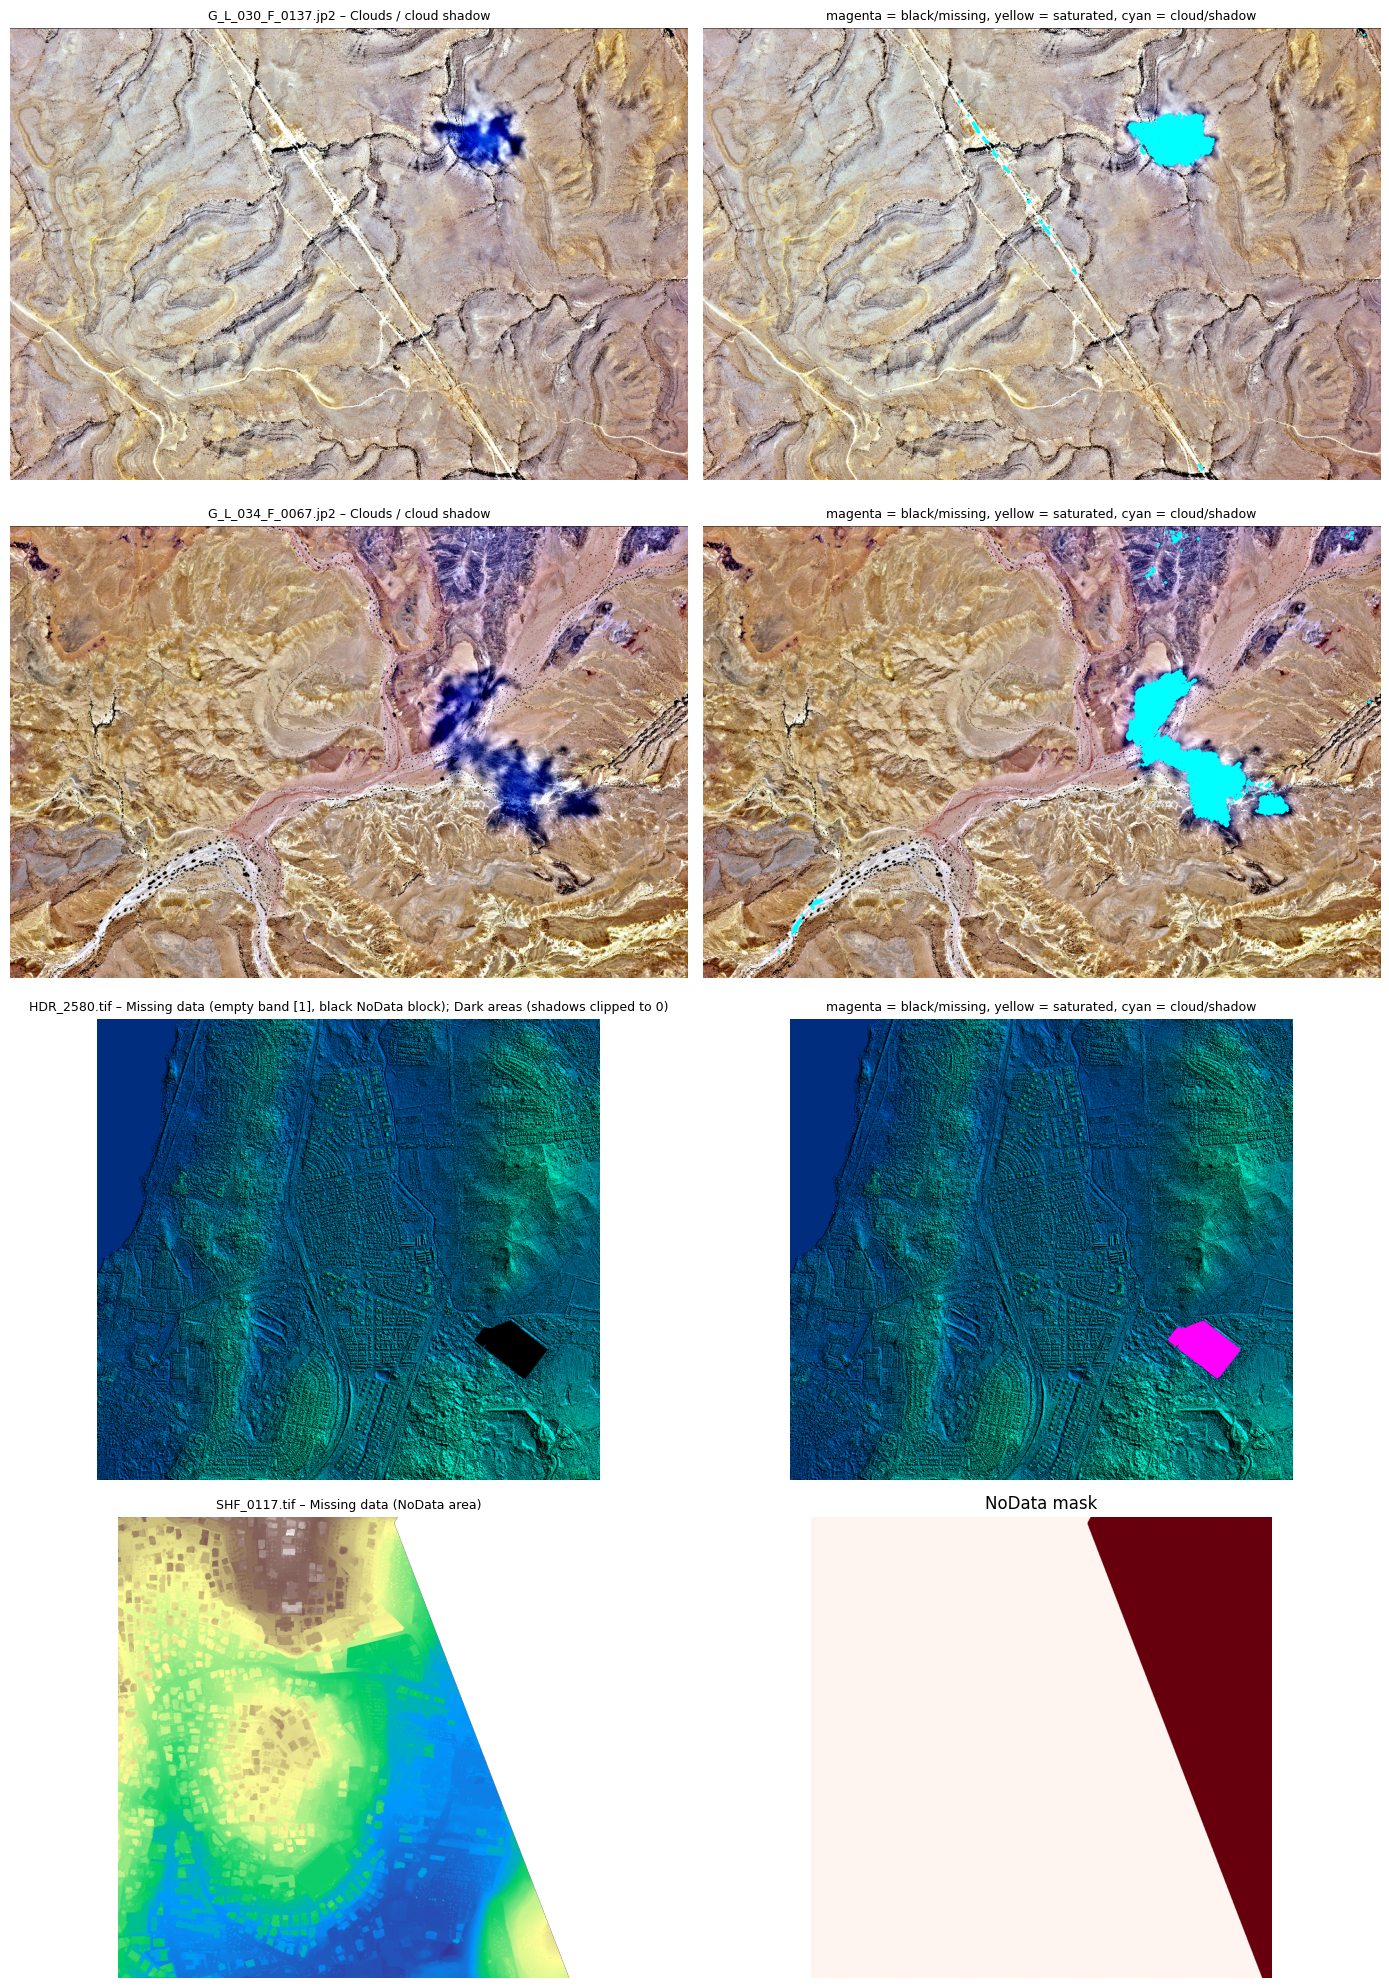

In [13]:
bad = [n for n in cache if q3_metrics.set_index("File").loc[n, "Status"] == "Invalid"]
fig, axes = plt.subplots(len(bad), 2, figsize=(14, 5 * len(bad)))
axes = np.atleast_2d(axes)
for row, name in zip(axes, bad):
    c = cache[name]; d = c["data"]
    if c["is_float"]:
        row[0].imshow(d[0], cmap="terrain")
        row[1].imshow(np.ma.getmaskarray(d[0]), cmap="Reds"); row[1].set_title("NoData mask")
    else:
        rgb = np.dstack([stretch(d[i]) for i in range(3)])
        row[0].imshow(rgb)
        overlay = rgb.copy()
        mk = masks_all[name]
        overlay[mk["black"]] = [1, 0, 1]          # magenta = black / missing
        overlay[mk["saturated"]] = [1, 1, 0]      # yellow  = saturated
        overlay[mk["cloud"]] = [0, 1, 1]          # cyan    = cloud / shadow
        row[1].imshow(overlay)
        row[1].set_title("magenta = black/missing, yellow = saturated, cyan = cloud/shadow", fontsize=9)
    row[0].set_title(f"{name} – {q3_metrics.set_index('File').loc[name, 'Defect type']}", fontsize=9)
    for a in row: a.axis("off")
plt.tight_layout()
plt.show()

### Notes on the defects found

* **G_L_030_F_0137 / G_L_034_F_0067 – clouds / cloud shadow.** Soft greyish-blue, low-saturation patches (about 1 % and 2 % of the frame in the largest blob). Inside them R and G fall by about 25–30 DN while B rises slightly, and the ground texture is blurred. That fits thin clouds between the camera and the ground, plus the shadows they cast (shadowed ground is lit only by blue skylight).
* **HDR_2580 – missing data + dark areas.** The red band is entirely empty. About 19 % of pixels are 0 in all bands: shadows/dark surfaces clipped to black, plus a solid black polygon with no data (east part of the tile).
* **SHF_0117 – missing data.** About 21 % NoData (−32767), a triangular area on the east side of the tile.
* **KSB_1626 – valid.** About 1.5 % of pixels reach 255, but almost only in band 3, on scattered bright roofs and concrete (bands 1/2 there are ≈ 220, NDVI ≈ 0). Only 0.05 % are clipped white in all RGB bands, and there is no connected clipped area (largest spot ≈ 0.02 % of the tile). Band 3 simply has the highest level in the tile (mean 140 vs 125/119), so the brightest surfaces clip in that channel first. The image looks normal: no area has lost its information, so this is not a defect.
* **HEF_2000, TLY_1226 – valid.** No NoData, no clipping, no clouds (TLY's sea is a homogeneous surface, not a defect).